In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import math

In [44]:
clinical_data = pd.read_csv("clinical_data.csv")
lab_data1 = pd.read_csv("lab_data.csv")

Filtering data for 30 days

In [45]:
preop = lab_data1[(lab_data1['dt'] < 0) & (lab_data1['dt'] >= -2592000)] #30 days

preop_last = (preop.sort_values('dt').groupby(['caseid', 'name']).last()   
              .reset_index()[['caseid','dt', 'name', 'result']])

preop_last.head(10)
print("pre-op rows:", len(preop))

pre-op rows: 196862


In [46]:
preop.groupby("name")["dt"].describe()
print("median hours before surgery:", (preop_last["dt"].abs()/3600).median())

median hours before surgery: 29.634444444444444


In [47]:
lab_data = (preop_last
            .pivot(index="caseid", columns="name", values="result")
            .reset_index())
lab_data.columns.name = None

lab_cols = [c for c in lab_data.columns if c != "caseid"]
lab_data[lab_cols] = lab_data[lab_cols].apply(pd.to_numeric, errors="coerce")

lab_data.head(10)
print(lab_data.shape)
print(clinical_data.shape)

(5388, 35)
(6388, 74)


filtering columns that have more than 75 missing data

In [48]:
missing_rate = lab_data.isna().mean()
lab_data = lab_data.loc[:, missing_rate < 0.75]
print("after 75% filter:", lab_data.shape)
lab_data


after 75% filter: (5388, 24)


,caseid,alb,alt,aptt,ast,bun,cl,cr,crp,fib,...,k,na,p,plt,pt%,ptinr,ptsec,tbil,tprot,wbc
0,1,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,...,3.5,141.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,NaN,NaN,NaN,NaN,NaN,115.0,NaN,NaN,NaN,...,4.7,143.0,NaN,251.0,NaN,NaN,NaN,NaN,NaN,4.36
2,4,NaN,NaN,NaN,NaN,NaN,108.0,NaN,NaN,NaN,...,4.3,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5,4.6,30.0,36.5,64.0,27.0,108.0,1.83,NaN,178.0,...,4.9,139.0,5.4,158.0,81.0,1.14,13.0,0.9,8.2,14.64
4,6,3.9,17.0,29.1,19.0,14.0,104.0,1.07,0.01,183.0,...,3.4,141.0,2.8,145.0,104.0,0.97,11.1,1.0,6.7,3.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5383,6384,NaN,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,...,4.2,143.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5384,6385,3.7,28.0,NaN,18.0,19.0,109.0,0.84,NaN,NaN,...,4.0,144.0,NaN,239.0,NaN,NaN,NaN,0.6,5.9,5.45
5385,6386,NaN,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,...,4.5,142.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5386,6387,4.4,10.0,32.2,16.0,7.0,103.0,0.65,0.03,239.0,...,3.6,142.0,3.0,214.0,90.0,1.07,12.2,0.3,6.9,7.70


Remove physiologically impossible values only

In [49]:
lab_data = lab_data[lab_data["hct"].between(10, 65) | lab_data["hct"].isna()]
for c in ["height", "weight", "bmi"]:
    clinical_data.loc[clinical_data[c] <= 0, c] = np.nan
print("lab_data after plausibility filter:", lab_data.shape)
print("clinical_data after plausibility filter:", clinical_data.shape)

lab_data after plausibility filter: (5388, 24)
clinical_data after plausibility filter: (6388, 74)


Fix the syntax error in data

In [50]:
clinical_data["age"] = clinical_data["age"].replace(">89", 90)
clinical_data["age"] = pd.to_numeric(clinical_data["age"], errors="coerce")

Merge 2 dataframes with common IDs

In [51]:
import pandas as pd
from scipy.stats import pearsonr

merged_data = clinical_data.merge(lab_data, on="caseid", how="inner")

In [52]:
import pandas as pd
from scipy.stats import pearsonr

merged_data = clinical_data.merge(lab_data, on="caseid", how="inner")
merged_data["sex_bin"] = (merged_data["sex"] == "M").astype(int)

predictors = ["sex_bin", "age", "height", "weight", "bmi"]

results = []
for col in predictors:
    sub = merged_data[[col, "hct"]].dropna()   # pairwise deletion, like .corr()
    r, p = pearsonr(sub[col], sub["hct"])
    results.append({"variable": col, "pearson_r": r, "p_value": p, "n": len(sub)})

corr_df = pd.DataFrame(results)
print(corr_df)

  variable  pearson_r        p_value     n
0  sex_bin   0.241466   5.681913e-56  4138
1      age  -0.061301   7.950962e-05  4138
2   height   0.257384   1.323553e-63  4138
3   weight   0.365879  2.846304e-131  4138
4      bmi   0.265882   6.616834e-68  4138


This is the dataframe on which we will build our ML models

In [53]:
merged_data = merged_data.dropna(subset=['hct','sex_bin','height','weight','bmi'])
merged_data


,caseid,subjectid,casestart,caseend,anestart,aneend,opstart,opend,adm,dis,...,na,p,plt,pt%,ptinr,ptsec,tbil,tprot,wbc,sex_bin
1,2,2487,0,15741,-1039,14921.000000,1721,14621,-221160,1506840,...,143.0,NaN,251.0,NaN,NaN,NaN,NaN,NaN,4.36,1
3,5,4416,0,21531,-1009,22391.000000,2591,20291,-67560,3734040,...,139.0,5.4,158.0,81.0,1.14,13.0,0.9,8.2,14.64,1
4,6,5586,0,5145,-51,4749.000000,2649,4449,-300600,131400,...,141.0,2.8,145.0,104.0,0.97,11.1,1.0,6.7,3.20,0
5,7,5124,0,15770,477,14817.000000,3177,14577,-154320,623280,...,139.0,NaN,229.0,109.0,0.95,10.8,0.4,7.4,4.28,0
8,11,3963,0,5265,-222,5117.999999,618,4518,-135540,37260,...,141.0,NaN,261.0,121.0,0.90,10.2,0.3,5.8,6.31,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5381,6382,5436,0,6876,-136,6764.000000,764,5864,-227820,204180,...,141.0,3.2,323.0,111.0,0.94,10.7,0.9,6.9,5.22,0
5382,6383,4255,0,23242,-1883,23137.000000,3037,22641,-224040,812760,...,141.0,4.8,202.0,114.0,0.92,10.5,0.6,6.5,5.01,1
5384,6385,2278,0,20643,-544,20996.000000,2396,19496,-225600,1675200,...,144.0,NaN,239.0,NaN,NaN,NaN,0.6,5.9,5.45,1
5386,6387,5230,0,12025,-550,12830.000000,1730,11030,-227760,377040,...,142.0,3.0,214.0,90.0,1.07,12.2,0.3,6.9,7.70,0


# Predictive Mining Tasks with Kernel Ridge Model 

In [54]:
# 1. Import libraries for predictive modeling
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    confusion_matrix,
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

In [55]:
# 2. Select the four predictors and define the Kernel Ridge pipeline
# Target: hct | Predictors: sex, height, weight, and bmi
# sex_bin represents sex numerically: male = 1 and female = 0.
feature_columns = ["sex_bin", "height", "weight", "bmi"]
X = merged_data[feature_columns]
y = merged_data["hct"]

# Imputation and scaling are fitted only on training data in each fold.
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kernel_ridge", KernelRidge(kernel="rbf", alpha=1.0, gamma=None)),
])

print("Target: hct")
print("Predictors: sex, height, weight, bmi")
print("Number of samples:", len(X))

Target: hct
Predictors: sex, height, weight, bmi
Number of samples: 4138


In [56]:
# 3. Generate out-of-fold predictions with 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
y_pred_cv = cross_val_predict(model, X, y, cv=cv, n_jobs=-1)

cv_mse = mean_squared_error(y, y_pred_cv)
cv_rmse = np.sqrt(cv_mse)
cv_mae = mean_absolute_error(y, y_pred_cv)

print("5-fold cross-validation results")
print(f"Mean Squared Error (MSE): {cv_mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {cv_rmse:.4f}")
print(f"Mean Absolute Error (MAE): {cv_mae:.4f}")

5-fold cross-validation results
Mean Squared Error (MSE): 26.3955
Root Mean Squared Error (RMSE): 5.1377
Mean Absolute Error (MAE): 3.9306


In [57]:
# 4. Convert continuous HCT predictions to low/not-low classes
# These classes are used for the score overview at the end.
# Low HCT: male < 40%, female < 36%.
hct_threshold = np.where(X["sex_bin"].to_numpy() == 1, 40.0, 36.0)
y_true_low = (y.to_numpy() < hct_threshold).astype(int)
y_pred_low = (y_pred_cv < hct_threshold).astype(int)

Test-set results
Mean Squared Error (MSE): 24.7939
Root Mean Squared Error (RMSE): 4.9793
Mean Absolute Error (MAE): 3.8269


,Actual HCT,Predicted HCT,Absolute Error
4834,30.0,42.70,12.70
3480,44.0,39.34,4.66
4273,40.4,36.69,3.71
307,38.4,36.35,2.05
4710,44.2,39.08,5.12
3796,42.8,37.11,5.69
2582,36.3,36.35,0.05
4051,41.0,40.59,0.41
562,28.7,37.37,8.67
2290,35.8,38.14,2.34


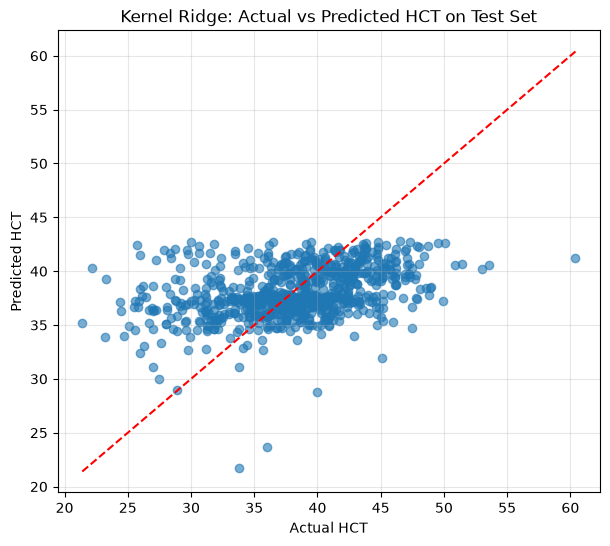

In [58]:
# 5. Train/test split and test-set predictions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model.fit(X_train, y_train)
y_test_pred = model.predict(X_test)

test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_mae = mean_absolute_error(y_test, y_test_pred)

print("Test-set results")
print(f"Mean Squared Error (MSE): {test_mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {test_rmse:.4f}")
print(f"Mean Absolute Error (MAE): {test_mae:.4f}")

# Display actual values beside test predictions.
test_predictions = pd.DataFrame({
    "Actual HCT": y_test,
    "Predicted HCT": y_test_pred,
})
test_predictions["Absolute Error"] = (
    test_predictions["Actual HCT"] - test_predictions["Predicted HCT"]
).abs()

display(test_predictions.head(20).round(2))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred, alpha=0.6)
plot_min = min(y_test.min(), y_test_pred.min())
plot_max = max(y_test.max(), y_test_pred.max())
plt.plot([plot_min, plot_max], [plot_min, plot_max], "r--")
plt.xlabel("Actual HCT")
plt.ylabel("Predicted HCT")
plt.title("Kernel Ridge: Actual vs Predicted HCT on Test Set")
plt.grid(alpha=0.3)
plt.show()

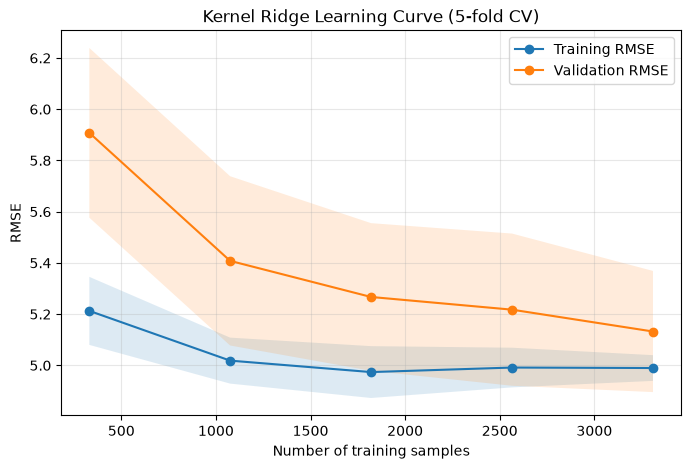

In [59]:
# 6. Learning curve: training and validation RMSE versus training-set size
from sklearn.model_selection import learning_curve

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    cv=cv,
    train_sizes=np.linspace(0.1, 1.0, 5),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

train_rmse = -train_scores
validation_rmse = -validation_scores
train_rmse_mean = train_rmse.mean(axis=1)
train_rmse_std = train_rmse.std(axis=1)
validation_rmse_mean = validation_rmse.mean(axis=1)
validation_rmse_std = validation_rmse.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse_mean, "o-", label="Training RMSE")
plt.plot(train_sizes, validation_rmse_mean, "o-", label="Validation RMSE")
plt.fill_between(
    train_sizes,
    train_rmse_mean - train_rmse_std,
    train_rmse_mean + train_rmse_std,
    alpha=0.15,
)
plt.fill_between(
    train_sizes,
    validation_rmse_mean - validation_rmse_std,
    validation_rmse_mean + validation_rmse_std,
    alpha=0.15,
)
plt.xlabel("Number of training samples")
plt.ylabel("RMSE")
plt.title("Kernel Ridge Learning Curve (5-fold CV)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

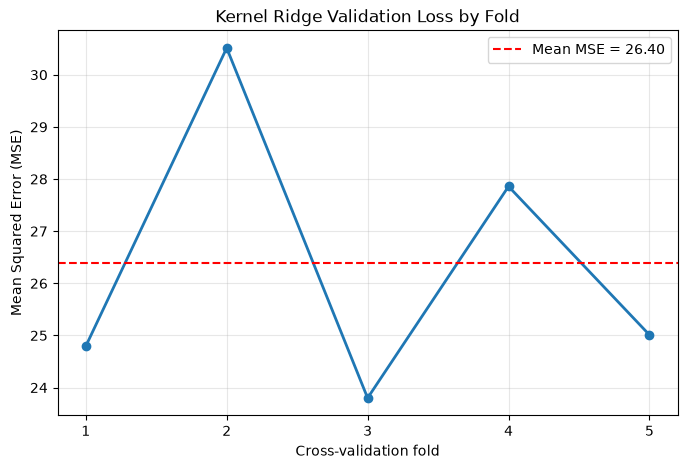

In [60]:
# 7. Loss curve: validation MSE for each cross-validation fold
# Kernel Ridge has no epoch-by-epoch loss because it is fitted directly.
fold_numbers = []
fold_mse_values = []

for fold_number, (_, validation_index) in enumerate(cv.split(X), start=1):
    fold_mse = mean_squared_error(
        y.iloc[validation_index],
        y_pred_cv[validation_index],
    )
    fold_numbers.append(fold_number)
    fold_mse_values.append(fold_mse)

plt.figure(figsize=(8, 5))
plt.plot(fold_numbers, fold_mse_values, marker="o", linewidth=2)
plt.axhline(
    np.mean(fold_mse_values),
    color="red",
    linestyle="--",
    label=f"Mean MSE = {np.mean(fold_mse_values):.2f}",
)
plt.xticks(fold_numbers)
plt.xlabel("Cross-validation fold")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Kernel Ridge Validation Loss by Fold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [61]:
# 8. Final classification-score overview for low-HCT prediction
# Scores are based on the out-of-fold predictions from 5-fold CV.
tn, fp, fn, tp = confusion_matrix(y_true_low, y_pred_low, labels=[0, 1]).ravel()

specificity = tn / (tn + fp) if (tn + fp) else 0.0
negative_predictive_value = tn / (tn + fn) if (tn + fn) else 0.0

score_overview = pd.DataFrame({
    "Score": [
        accuracy_score(y_true_low, y_pred_low),
        balanced_accuracy_score(y_true_low, y_pred_low),
        precision_score(y_true_low, y_pred_low, zero_division=0),
        recall_score(y_true_low, y_pred_low, zero_division=0),
        specificity,
        f1_score(y_true_low, y_pred_low, zero_division=0),
        negative_predictive_value,
        roc_auc_score(y_true_low, hct_threshold - y_pred_cv),
    ]
}, index=[
    "Accuracy",
    "Balanced Accuracy",
    "Precision (PPV)",
    "Recall / Sensitivity",
    "Specificity",
    "F1 Score",
    "Negative Predictive Value",
    "ROC-AUC",
])

print("Final low-HCT score overview (5-fold cross-validation)")
display(score_overview.round(4))

print("Detailed score report")
report = classification_report(
    y_true_low,
    y_pred_low,
    labels=[0, 1],
    target_names=["Not low HCT", "Low HCT"],
    output_dict=True,
    zero_division=0,
)
display(pd.DataFrame(report).transpose().round(4))

print(f"Counts used to calculate the scores: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Final low-HCT score overview (5-fold cross-validation)


,Score
Accuracy,0.6160
Balanced Accuracy,0.6103
Precision (PPV),0.5757
Recall / Sensitivity,0.5543
Specificity,0.6664
F1 Score,0.5648
Negative Predictive Value,0.6468
ROC-AUC,0.6444


Detailed score report


,precision,recall,f1-score,support
Not low HCT,0.6468,0.6664,0.6564,2278.000
Low HCT,0.5757,0.5543,0.5648,1860.000
accuracy,0.6160,0.6160,0.6160,0.616
macro avg,0.6112,0.6103,0.6106,4138.000
weighted avg,0.6148,0.6160,0.6152,4138.000


Counts used to calculate the scores: TN=1518, FP=760, FN=829, TP=1031
